# 11 — Shortcut dependence: an analytic distribution shift

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/brains-to-models/blob/main/code/notebooks/11_shortcut_dependence.ipynb)

**Related resources:** [Paper](https://github.com/arvidl/brains-to-models/blob/main/paper/main.pdf) · [Presentation guide](https://github.com/arvidl/brains-to-models/blob/main/talk/resources.md)

## Why this notebook

A predictor can be very accurate in one population because an incidental marker happens to agree with the target. If that agreement changes, the same unchanged rule can fail. This notebook constructs the relationship exactly, without training a network or using images.

An exact binary construction lets you track which variables change across populations. You will derive each rule's expected accuracy, construct those frequencies in 200 cases and identify what additional observations would test a trained model's input dependence.

### Learning goals

1. Derive a marker rule's accuracy from marker–target agreement.
2. Distinguish a changed predictor from a changed evaluation distribution.
3. Explain why overall 50% agreement is not generally a proof of independence.
4. Design a test that would establish input dependence in a trained model.


## Concepts and two reading paths

<details open>
<summary><strong>For biomedical and imaging readers</strong></summary>

**Target** is the binary outcome to predict. A **marker** is a second binary variable that may correlate with it. A **shortcut rule** predicts from that marker, even if the intended interpretation would rely on another feature. The notebook creates labels and predictions directly; it does not determine what a network chose to use.

**Distribution shift** changes the population relationship among variables. The marker rule itself stays fixed. **Stable feature** is a role assigned to the comparison variable in this construction. Demonstrating stability in a hospital dataset would require new evidence, especially when disease spectrum, prevalence, acquisition and labels also vary.

Read the accuracy curve as a conditional statement: if marker agreement is $a$, this rule's accuracy is $a$. A clinically relevant estimate would need measurements of the actual rule and population.

</details>

<details>
<summary><strong>For computational readers</strong></summary>

The marker rule is $\hat Y_M=M$, so $P(\hat Y_M=Y)=P(M=Y)$ by definition. Shifting $P(M,Y)$ changes its accuracy without changing the rule. The stable comparison imposes $P(S=Y)=0.8$ in all three populations.

In a balanced binary population, independence is obtained here by imposing $P(M=1\mid Y=0)=P(M=1\mid Y=1)=1/2$. All four joint cells then have probability $1/4$. Overall agreement of one half in a different, potentially imbalanced construction would not suffice.

Exact case counts remove sampling variability from the displayed accuracies. Random seeds choose which cases carry errors, not how many. Error bars would misrepresent these imposed finite frequencies as estimates from a separate random-sampling process.

</details>


### Run in Colab or locally

**Colab:** click **Open in Colab**, connect to a standard **CPU** runtime, and run the setup cell followed by the remaining cells (**Runtime → Run all**). Setup obtains the shared code and numerical dependencies.

**Locally:** follow the [environment instructions](https://github.com/arvidl/brains-to-models/blob/main/README.md#run-the-notebooks) and select the project's Python kernel in Cursor or JupyterLab. Setup locates the checkout and sets the working directory to `code/notebooks`, so `%load ../solutions/<filename>.py` works in either environment.

Use **File → Save a copy in Drive** to retain Colab notebook edits, and download generated files before the runtime ends. See the [execution guide](https://github.com/arvidl/brains-to-models/blob/main/code/notebooks/README.md#running-and-saving) for saving outputs and starting a fresh runtime.


In [1]:
# Locate the shared code locally, or download a small checkout in Colab.
import os
from pathlib import Path
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = os.environ.get("BRAINSMODELS_REPO_URL",
                          "https://github.com/arvidl/brains-to-models.git")
if IN_COLAB:
    root = Path(os.environ.get("BRAINSMODELS_COLAB_ROOT",
                               "/content/brains-to-models"))
    if not (root / "code/src/brainsmodels").is_dir():
        # Sparse checkout keeps the large presentation out of the runtime.
        subprocess.check_call(["git", "clone", "--depth", "1", "--filter=blob:none",
                               "--sparse", "--branch", "main", REPO_URL, str(root)])
        subprocess.check_call(["git", "-C", str(root), "sparse-checkout", "set",
                               "code", "paper/figures"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "numpy>=1.26", "matplotlib>=3.8"])
else:
    here = Path.cwd().resolve()
    root = next((p for p in (here, *here.parents)
                 if (p / "pyproject.toml").is_file()
                 and (p / "code/src/brainsmodels").is_dir()), None)
    if root is None:
        raise RuntimeError("Open this notebook inside a brains-to-models checkout, "
                           "or use its Open in Colab badge.")

src = str(root / "code/src")
if src not in sys.path:
    sys.path.insert(0, src)
# Keep relative exercise paths consistent in Colab, JupyterLab and Cursor.
os.chdir(root / "code/notebooks")
repo = ROOT = root
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
print("Checkout:", root)
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__)
# End of shared setup.

from brainsmodels.paper_examples import SHORTCUT_AGREEMENTS, STABLE_ACCURACY, shortcut_dependence

get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"figure.dpi": 115, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
OUTPUT = ROOT / ".build/paper-examples/11_shortcut_dependence"

OUTPUT.mkdir(parents=True, exist_ok=True)

def show_figure(fig, name):
    fig.savefig(OUTPUT / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


Checkout: CHECKOUT
Python: 3.12.2 | NumPy: 2.5.2


## 1. State the data-generating assumptions

Let $Y\in\{0,1\}$ be the target and $M\in\{0,1\}$ an ancillary marker (for example, a toy site cue).
The marker rule predicts $\hat Y_M=M$. Define agreement $a=P(M=Y)$. Then, by definition,

$$\mathrm{accuracy}(\hat Y_M)=P(M=Y)=a.$$

A second fixed rule uses a stable feature, $\hat Y_S=S$, and is **stipulated** to have
$P(S=Y)=0.80$ in every population. This assumption isolates the effect of marker dependence;
it is not evidence that such a stable rule has been found in real images.

The paper selects $a=0.95$ (training-like), $0.50$ (independent in our balanced construction below)
and $0.05$ (reversed). Equal agreement to 50% alone does not establish statistical independence
in an arbitrary dataset; we will enforce it within each target class here.


In [2]:
population_names = list(SHORTCUT_AGREEMENTS)
agreements = np.array(list(SHORTCUT_AGREEMENTS.values()))
example = shortcut_dependence(agreements)
reference = json.loads((ROOT / "paper/figures/computed_values.json").read_text())["shortcut_accuracy"]
assert reference == {**SHORTCUT_AGREEMENTS, "stable_rule": STABLE_ACCURACY}
np.testing.assert_array_equal(example.marker_accuracy, [.95, .50, .05])
np.testing.assert_array_equal(example.stable_accuracy, [.80, .80, .80])
print("Population        Marker accuracy   Stable accuracy (assumed)")
for name, marker, stable in zip(population_names, example.marker_accuracy, example.stable_accuracy):
    print(f"{name:16}  {marker:>7.0%}           {stable:>7.0%}")


Population        Marker accuracy   Stable accuracy (assumed)
training_like         95%               80%
independent           50%               80%
reversed               5%               80%


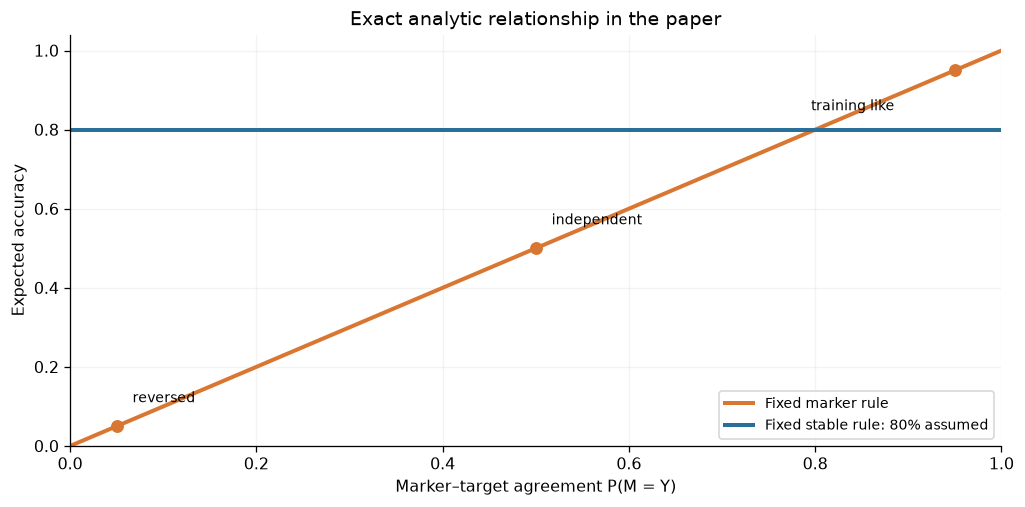

In [3]:
curve = shortcut_dependence()
blue, orange = "#2a6f97", "#d97732"
fig, ax = plt.subplots(figsize=(8.8, 4.3), layout="constrained")
ax.plot(curve.agreement, curve.marker_accuracy, color=orange, lw=2.5, label="Fixed marker rule")
ax.plot(curve.agreement, curve.stable_accuracy, color=blue, lw=2.5,
        label="Fixed stable rule: 80% assumed")
ax.scatter(agreements, example.marker_accuracy, color=orange, s=50, zorder=3)
for name, a in zip(population_names, agreements):
    ax.annotate(name.replace("_", " "), (a, a), xytext=(-90 if a > .8 else 10, -25 if a > .8 else 15),
                textcoords="offset points", fontsize=9)
ax.set(xlabel="Marker–target agreement P(M = Y)", ylabel="Expected accuracy",
       xlim=(0, 1), ylim=(0, 1.04), title="Exact analytic relationship in the paper")
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=.15)
show_figure(fig, "shortcut_accuracy")


**Result.** The marker rule achieves 95%, 50% and 5%. The stable rule stays at its stipulated 80%.
In this construction, accuracy on one population cannot distinguish a stable predictor from
one that exploits a marker whose agreement will change.

## 2. Construct 200 cases with exactly these frequencies

Keep 100 cases of each target class and the **same** stable predictions in every population.
Make the stable rule wrong on 20 cases per class. For the marker rule, change only marker agreement:
flip the marker on 5, 50 or 95 cases per class. A fixed seed selects which cases change;
counts are imposed, so these are exact finite frequencies without sampling error bars.
The construction contains binary variables, not images, hospitals or patient records.


In [4]:
rng = np.random.default_rng(7)
labels = np.tile([0, 1], 100)
class_orders = [rng.permutation(np.flatnonzero(labels == y)) for y in (0, 1)]
stable_predictions = labels.copy()
for order in class_orders:
    stable_predictions[order[:20]] ^= 1
assert np.mean(stable_predictions == labels) == STABLE_ACCURACY

markers = {}
for name, agreement in SHORTCUT_AGREEMENTS.items():
    marker = labels.copy()
    errors_per_class = int(round(100 * (1 - agreement)))
    for order in class_orders:
        marker[order[:errors_per_class]] ^= 1
    markers[name] = marker
    assert np.mean(marker == labels) == agreement
    for y in (0, 1):
        assert np.mean(marker[labels == y] == y) == agreement

# For the independent population, both conditional marker probabilities are exactly 1/2.
joint = np.array([[np.mean((labels == y) & (markers["independent"] == m))
                   for m in (0, 1)] for y in (0, 1)])
np.testing.assert_array_equal(joint, np.full((2, 2), .25))
print("Independent population: rows Y=0/1, columns M=0/1")
print(joint)
print("Full 200-case empirical accuracies:")
for name in population_names:
    print(f"{name:16} marker={np.mean(markers[name] == labels):.0%}; "
          f"stable={np.mean(stable_predictions == labels):.0%}")


Independent population: rows Y=0/1, columns M=0/1
[[0.25 0.25]
 [0.25 0.25]]
Full 200-case empirical accuracies:
training_like    marker=95%; stable=80%
independent      marker=50%; stable=80%
reversed         marker=5%; stable=80%


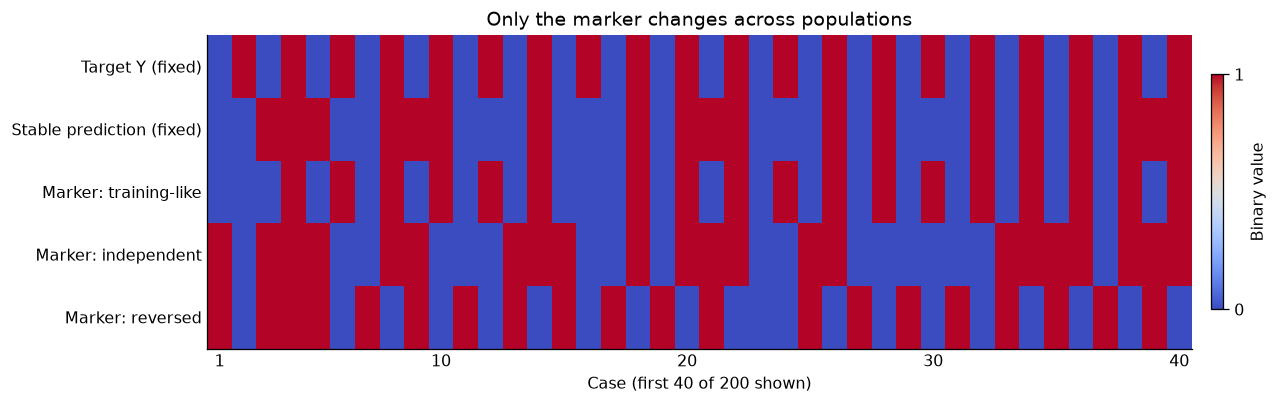

In [5]:
rows = np.stack([labels, stable_predictions, *[markers[name] for name in population_names]])
fig, ax = plt.subplots(figsize=(11, 3.4), layout="constrained")
image = ax.imshow(rows[:, :40], cmap="coolwarm", vmin=0, vmax=1, aspect="auto", interpolation="nearest")
ax.set(yticks=range(5), yticklabels=["Target Y (fixed)", "Stable prediction (fixed)",
       "Marker: training-like", "Marker: independent", "Marker: reversed"],
       xlabel="Case (first 40 of 200 shown)", xticks=[0, 9, 19, 29, 39],
       xticklabels=[1, 10, 20, 30, 40], title="Only the marker changes across populations")
ax.tick_params(length=0)
bar = fig.colorbar(image, ax=ax, ticks=[0, 1], shrink=.75, pad=.02)
bar.set_label("Binary value")
show_figure(fig, "fixed_targets_changing_markers")


The displayed 40 cases illustrate individual changes; all reported accuracies use all 200 cases.
The target and stable prediction stay fixed by construction. No optimizer, feature learner or
test-set selection is involved.

## 3. Change the assumptions explicitly

Edit `new_agreement` and `new_stable_accuracy` below. Predict where the two rules exchange rank.
Their expected accuracies are equal at $a=P(S=Y)$. Try lowering stable accuracy as well:
stability under shift must be tested, not inferred from this picture.


In [6]:
new_agreement = .65
new_stable_accuracy = .80
intervention = shortcut_dependence([new_agreement], stable_accuracy=new_stable_accuracy)
print(f"Marker: {intervention.marker_accuracy[0]:.0%}; "
      f"assumed stable rule: {intervention.stable_accuracy[0]:.0%}")
(OUTPUT / "results.json").write_text(json.dumps({
    "model_trained": False, "cases": len(labels),
    "marker_accuracies": {name: float(np.mean(marker == labels)) for name, marker in markers.items()},
    "stable_accuracy_assumed": STABLE_ACCURACY,
    "independent_joint_probabilities": joint.tolist(),
}, indent=2))


Marker: 65%; assumed stable rule: 80%


295

## From an analytic possibility to an empirical test

The marker rule beats the stipulated stable rule at 95% agreement and loses at 50% or 5%. This establishes that a rule can change rank under shift. It does not prove that an optimizer will choose that rule, that a particular hospital has such a marker or that another measured feature will remain stable.

Inspect the 200-case construction. Labels and stable predictions remain fixed while marker bits change. The first 40 columns are only a view of those cases; the reported accuracies use all 200. Changing the subset displayed must not be confused with changing the population measurement.

### Design a follow-up for a trained model

Identify a candidate marker and specify an intervention that preserves the target-relevant structure. Evaluate the same fixed model before and after the intervention. Check whether the edit introduces artifacts or changes legitimate evidence. Combine this with held-out populations where the marker–target relationship differs. No single test automatically establishes that all important shortcuts have been removed.

Notebook 09 supplies learned synthetic models and explicit channel replacements. Notebook 08 preserves a central pattern while changing a marker-like intensity in a known function. These are complementary teaching resources: an analytic construction, a learned-model intervention and a transparent parameterized calculation answer related but different questions.


## Reflection and study design

- What would an intervention on a site marker need to hold fixed to investigate a real model's dependence?
- Could a model use both the stable feature and the marker? These two fixed rules do not describe that case.
- Which measurements would justify calling an image feature stable across hospitals or time?
- Why does excellent training-like accuracy fail to establish that a rule uses the intended feature?

The 95%-to-5% reversal is a deliberately strong intervention on marker agreement. For a population-shift study, list which other quantities might change: prevalence, acquisition, target definition or label quality. Decide which measurements would be needed to distinguish those changes from a changed dependence on the marker.

**Further reading:** Geirhos et al. (2020), *Shortcut learning in deep neural networks*,
[doi:10.1038/s42256-020-00257-z](https://doi.org/10.1038/s42256-020-00257-z).
To run a trained synthetic segmentation model and probe its input channels, see
[notebook 09](https://github.com/arvidl/brains-to-models/blob/main/code/notebooks/09_segmentation_reflection.ipynb).
